Testar bild 1:


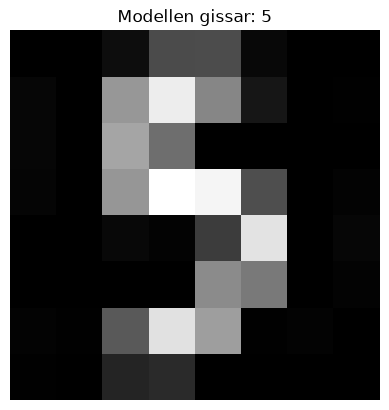

Testar bild 2:


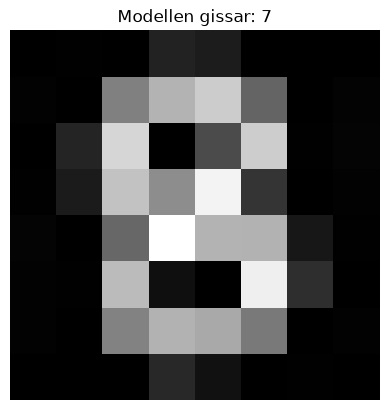

Testar bild 3:


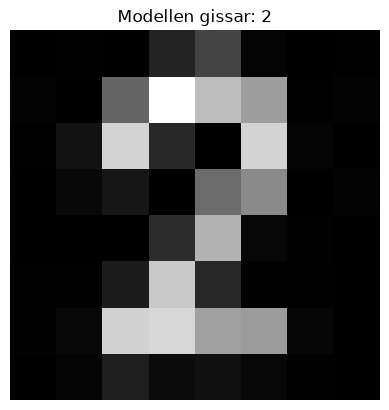

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from PIL import Image, ImageOps

# 1. Ladda MNIST-liknande dataset (8x8 pixlar)
digits = load_digits()
X = digits.data
y = digits.target

# 2. Träna modellen
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# Uppdaterad funktion som centrerar siffran ordentligt i mitten
def predict_my_image(image_path):
    # 1. Öppna bild och invertera (vit siffra på svart bakgrund)
    img = Image.open(image_path).convert('L')
    img = ImageOps.invert(img)
    
    # 2. Klipp bort 10% av ytterkanterna för att bli av med ramskuggor
    w, h = img.size
    img = img.crop((int(w * 0.10), int(h * 0.10), int(w * 0.90), int(h * 0.90)))
    
    # 3. Höj tröskelvärdet något så bara det mörka bläcket blir kvar (vitt)
    img = img.point(lambda p: 255 if p > 130 else 0)
    
    # 4. Hitta ram runt enbart siffran och beskära tätt
    bbox = img.getbbox()
    if bbox:
        img = img.crop(bbox)
    
    # 5. Gör kvadratisk och lägg till 30% marginal runt om för perfekt centrering
    w, h = img.size
    max_side = int(max(w, h) * 1.3)
    new_img = Image.new('L', (max_side, max_side), 0)
    new_img.paste(img, ((max_side - w) // 2, (max_side - h) // 2))
    
    # 6. Skala ner till 8x8 pixlar
    img_resized = new_img.resize((8, 8), Image.Resampling.LANCZOS)
    
    # 7. Omvandla till numpy-array (skala 0-16)
    img_array = np.array(img_resized, dtype=float)
    img_array = (img_array / 255.0) * 16.0
    
    # 8. Prediktera
    flat_array = img_array.flatten()
    prediction = model.predict([flat_array])[0]
    
    # Rita ut resultatet
    plt.imshow(img_array, cmap='gray')
    plt.title(f"Modellen gissar: {prediction}")
    plt.axis('off')
    plt.show()

# 4. Testa dina centrerade bilder!
print("Testar bild 1:")
predict_my_image('1.jpeg')

print("Testar bild 2:")
predict_my_image('2.jpeg')

print("Testar bild 3:")
predict_my_image('3.jpeg')